In [6]:
stoch_at_q = float(curve.loc[curve["Q"] == q_det, "expected_profit"].iloc[0])

summary = pd.DataFrame([{
    "assumed_fixed_demand": MEAN_DEMAND,
    "deterministic_optimal_Q": q_det,
    "deterministic_predicted_profit": det["best_profit"],
    "simulated_expected_profit_at_same_Q": round(stoch_at_q, 1),
    "prediction_gap": round(det["best_profit"] - stoch_at_q, 1),
}])
summary.to_csv(os.path.join(TABLES_DIR, "deterministic_optimal_summary.csv"), index=False)
summary

,assumed_fixed_demand,deterministic_optimal_Q,deterministic_predicted_profit,simulated_expected_profit_at_same_Q,prediction_gap
0,120,120,84000.0,76195.6,7804.4


## Module 09 summary
- Deterministic model: demand is assumed to be exactly 120 units, with no randomness.
- Verified the profit function against hand calculations for Q = 110, 120 and 130 (profits 75,000 / 84,000 / 75,000).
- Evaluated every integer Q from 0 to 500. Deterministic-optimal Q = 120, with predicted profit ₹84,000.
- Profit falls by ₹900 per unit on either side of 120, because overstocking costs c + h = ₹900 and understocking costs p − c + s = ₹900.
- At the same Q = 120, the Monte Carlo expected profit under Poisson(120) demand is ₹76,195.6. The deterministic prediction is ₹7,804.4 higher, because it ignores demand variability.
- The deterministic Q (120) equals the stochastic Q* (120) in the base case. Whether the two policies perform differently will be tested on independent scenarios in Module 10.
- All parameter values are illustrative assumptions and demand is synthetic.

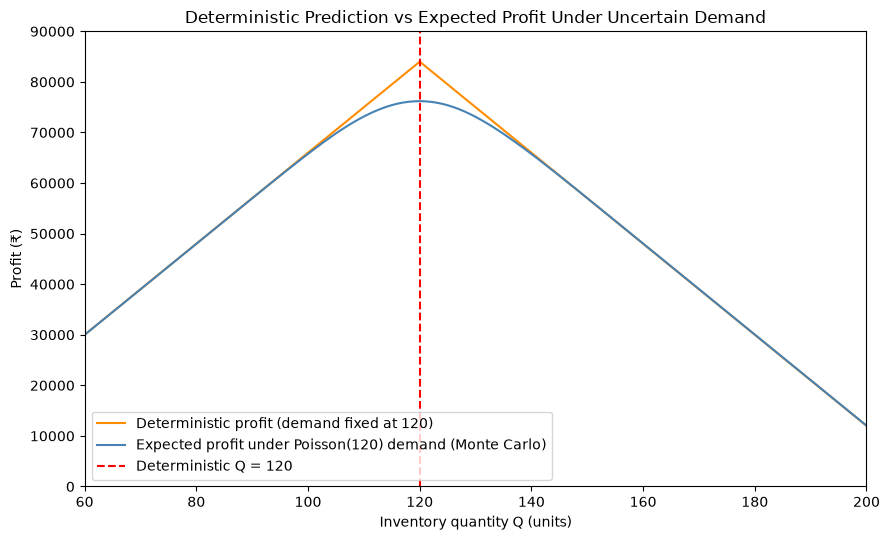

In [5]:
curve = pd.read_csv(os.path.join(TABLES_DIR, "expected_profit_by_Q.csv"))

plt.figure(figsize=(9, 5.5))
plt.plot(det["q_values"], det["profits"], color="darkorange",
         label="Deterministic profit (demand fixed at 120)")
plt.plot(curve["Q"], curve["expected_profit"], color="steelblue",
         label="Expected profit under Poisson(120) demand (Monte Carlo)")
plt.axvline(q_det, color="red", linestyle="--", label=f"Deterministic Q = {q_det}")
plt.xlim(60, 200)
plt.ylim(0, 90000)
plt.title("Deterministic Prediction vs Expected Profit Under Uncertain Demand")
plt.xlabel("Inventory quantity Q (units)")
plt.ylabel("Profit (₹)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "04_deterministic_profit_curve.png"), dpi=200)
plt.show()

In [4]:
q_det = det["best_q"]
lo, hi = max(q_det - 5, 0), min(q_det + 5, Q_MAX)

pd.DataFrame({
    "Q": det["q_values"][lo:hi + 1],
    "deterministic_profit": det["profits"][lo:hi + 1],
})

,Q,deterministic_profit
0,115,79500
1,116,80400
2,117,81300
3,118,82200
4,119,83100
5,120,84000
6,121,83100
7,122,82200
8,123,81300
9,124,80400


In [3]:
det = find_deterministic_q(MEAN_DEMAND, Q_MAX, **COSTS)

print("Number of Q values evaluated:", len(det["q_values"]))
print(f"Deterministic-optimal Q   : {det['best_q']} units")
print(f"Predicted profit at that Q: ₹{det['best_profit']:,.0f}")

Number of Q values evaluated: 501
Deterministic-optimal Q   : 120 units
Predicted profit at that Q: ₹84,000


In [2]:
# Q=110: 1500*110 - 800*110 - 200*10 = 165000 - 88000 - 2000 = 75000
# Q=120: 1500*120 - 800*120          = 180000 - 96000        = 84000
# Q=130: 1500*120 - 800*130 - 100*10 = 180000 - 104000 - 1000 = 75000
assert profit(110, 120, **COSTS) == 75000
assert profit(120, 120, **COSTS) == 84000
assert profit(130, 120, **COSTS) == 75000
print("Deterministic profit matches the hand calculations.")

Deterministic profit matches the hand calculations.


In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))
from src.parameters import COSTS, Q_MAX, MEAN_DEMAND
from src.profit import profit
from src.deterministic import find_deterministic_q

GRAPHS_DIR = os.path.join("..", "results", "graphs")
TABLES_DIR = os.path.join("..", "results", "tables")

print("Fixed demand assumed:", MEAN_DEMAND)
print("Costs:", COSTS)

Fixed demand assumed: 120
Costs: {'p': 1500, 'c': 800, 'h': 100, 's': 200}
